<a href="https://colab.research.google.com/github/lalkrishna-vp/sephora-customer-product-analysis/blob/main/week2_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files

uploaded = files.upload()


Saving product_info.csv to product_info.csv
Saving reviews_0-250.csv to reviews_0-250.csv


In [2]:

import pandas as pd
import os

for file in ["product_info.csv", "reviews_0-250.csv"]:
    print("\n" + "=" * 50)
    print("FILE:", file)

    if os.path.exists(file):
        df = pd.read_csv(file, nrows=5)

        print("Columns:", df.columns.tolist())
        print("\nFirst 3 rows:")
        display(df.head(3))
    else:
        print("File not found!")



FILE: product_info.csv
Columns: ['product_id', 'product_name', 'brand_id', 'brand_name', 'loves_count', 'rating', 'reviews', 'size', 'variation_type', 'variation_value', 'variation_desc', 'ingredients', 'price_usd', 'value_price_usd', 'sale_price_usd', 'limited_edition', 'new', 'online_only', 'out_of_stock', 'sephora_exclusive', 'highlights', 'primary_category', 'secondary_category', 'tertiary_category', 'child_count', 'child_max_price', 'child_min_price']

First 3 rows:


,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,P473671,Fragrance Discovery Set,6342,19-69,6320,3.6364,11,NaN,NaN,NaN,...,1,0,0,"['Unisex/ Genderless Scent', 'Warm &Spicy Scen...",Fragrance,Value & Gift Sets,Perfume Gift Sets,0,NaN,NaN
1,P473668,La Habana Eau de Parfum,6342,19-69,3827,4.1538,13,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,85.0,30.0
2,P473662,Rainbow Bar Eau de Parfum,6342,19-69,3253,4.2500,16,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0



FILE: reviews_0-250.csv
Columns: ['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd']

First 3 rows:


,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,1741593524,5,1.0,1.0,2,0,2,2023-02-01,I use this with the Nudestix “Citrus Clean Bal...,Taught me how to double cleanse!,NaN,brown,dry,black,P504322,Gentle Hydra-Gel Face Cleanser,NUDESTIX,19.0
1,1,31423088263,1,0.0,NaN,0,0,0,2023-03-21,I bought this lip mask after reading the revie...,Disappointed,NaN,NaN,NaN,NaN,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0
2,2,5061282401,5,1.0,NaN,0,0,0,2023-03-21,My review title says it all! I get so excited ...,New Favorite Routine,light,brown,dry,blonde,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0


In [3]:

import pandas as pd

# 1. Inspect product information
products = pd.read_csv("product_info.csv")

print("=== PRODUCT DATASET ===")
print("Rows:", len(products))
print("Columns:", len(products.columns))
print("Duplicate rows:", products.duplicated().sum())
print("\nMissing values:")
print(products.isnull().sum().sort_values(ascending=False).head(15))

if "rating" in products.columns:
    print("\nProduct rating distribution:")
    print(products["rating"].value_counts(
        dropna=False
    ).sort_index())

# 2. Inspect reviews in chunks to save memory
print("\n=== REVIEWS DATASET ===")

total_rows = 0
missing = None
rating_counts = None
duplicate_count = 0
columns = None

for chunk in pd.read_csv(
    "reviews_0-250.csv",
    chunksize=100_000
):
    total_rows += len(chunk)

    if columns is None:
        columns = chunk.columns.tolist()
        missing = pd.Series(0, index=columns, dtype="int64")

    missing += chunk.isnull().sum()

    duplicate_count += chunk.duplicated().sum()

    if "rating" in chunk.columns:
        counts = chunk["rating"].value_counts(dropna=False)
        rating_counts = counts if rating_counts is None else rating_counts.add(
            counts, fill_value=0
        )

print("Rows:", total_rows)
print("Columns:", len(columns))
print("Column names:", columns)
print("Duplicate rows within chunks:", duplicate_count)
print("\nMissing values:")
print(missing.sort_values(ascending=False).head(15))

if rating_counts is not None:
    print("\nReview rating distribution:")
    print(rating_counts.sort_index())


=== PRODUCT DATASET ===
Rows: 8494
Columns: 27
Duplicate rows: 0

Missing values:
sale_price_usd        8224
value_price_usd       8043
variation_desc        7244
child_max_price       5740
child_min_price       5740
highlights            2207
size                  1631
variation_value       1598
variation_type        1444
tertiary_category      990
ingredients            945
rating                 278
reviews                278
secondary_category       8
loves_count              0
dtype: int64

Product rating distribution:
rating
1.0000     12
1.1905      1
1.2500      1
1.3333      1
1.5000      2
         ... 
4.9825      1
4.9841      1
4.9937      1
5.0000    256
NaN       278
Name: count, Length: 4395, dtype: int64

=== REVIEWS DATASET ===


/tmp/ipykernel_1680/1762279822.py:28: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/tmp/ipykernel_1680/1762279822.py:28: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/tmp/ipykernel_1680/1762279822.py:28: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/tmp/ipykernel_1680/1762279822.py:28: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/tmp/ipykernel_1680/1762279822.py:28: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/tmp/ipykernel_1680/1762279822.py:28: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


Rows: 602130
Columns: 19
Column names: ['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd']
Duplicate rows within chunks: 0

Missing values:
helpfulness                 331832
review_title                167011
hair_color                  141081
eye_color                   138488
is_recommended              117486
skin_tone                   106056
skin_type                    74683
review_text                    999
rating                           0
Unnamed: 0                       0
author_id                        0
total_pos_feedback_count         0
submission_time                  0
total_feedback_count             0
total_neg_feedback_count         0
dtype: int64

Review rating distribution:
rating
1     32903
2     29253
3  

TOTAL REVIEWS: 602130

Rating summary:
        Review count  Percentage (%)
rating                              
1              32903            5.46
2              29253            4.86
3              44018            7.31
4             106956           17.76
5             389000           64.60

Average rating:
4.311837975188082


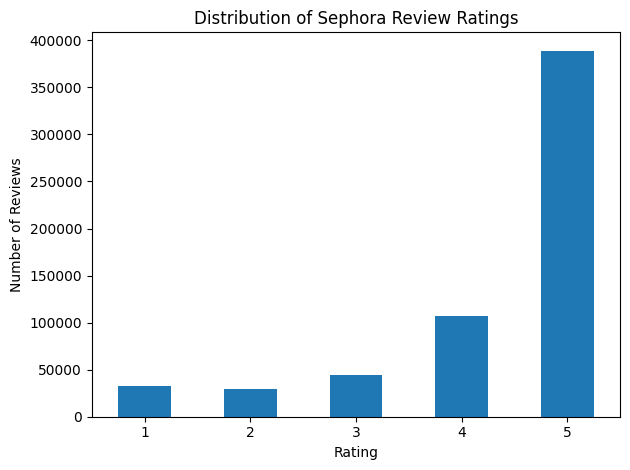

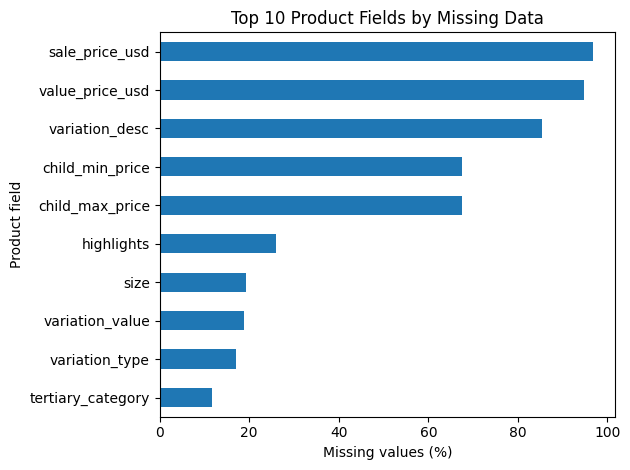

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# Read the reviews file in chunks and count ratings
rating_counts = pd.Series(dtype="int64")
review_rows = 0

for chunk in pd.read_csv(
    "reviews_0-250.csv",
    usecols=["rating"],
    chunksize=100_000,
    low_memory=False
):
    review_rows += len(chunk)
    rating_counts = rating_counts.add(
        chunk["rating"].value_counts(),
        fill_value=0
    )

rating_counts = rating_counts.sort_index().astype(int)

print("TOTAL REVIEWS:", review_rows)
print("\nRating summary:")
summary = pd.DataFrame({
    "Review count": rating_counts,
    "Percentage (%)": (
        rating_counts / review_rows * 100
    ).round(2)
})
print(summary)

print("\nAverage rating:")
print(
    (rating_counts.index.to_series() * rating_counts.values).sum()
    / rating_counts.sum()
)

# Graph 1: Rating distribution
rating_counts.plot(kind="bar")
plt.title("Distribution of Sephora Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Graph 2: Missing values in product data
products = pd.read_csv("product_info.csv")
missing_pct = (
    products.isnull().mean().mul(100)
    .sort_values(ascending=False)
    .head(10)
)

missing_pct.sort_values().plot(kind="barh")
plt.title("Top 10 Product Fields by Missing Data")
plt.xlabel("Missing values (%)")
plt.ylabel("Product field")
plt.tight_layout()
plt.show()


In [5]:

import pandas as pd

# Count recommendations and ratings using chunks
results = []

for chunk in pd.read_csv(
    "reviews_0-250.csv",
    usecols=["rating", "is_recommended"],
    chunksize=100_000,
    low_memory=False
):
    results.append(
        chunk.groupby(
            ["rating", "is_recommended"],
            dropna=False
        ).size().rename("count").reset_index()
    )

summary = pd.concat(results).groupby(
    ["rating", "is_recommended"],
    dropna=False
)["count"].sum().reset_index()

print("Rating and recommendation counts:")
display(summary)

# Calculate recommendation rates for each rating
valid = summary.dropna(subset=["is_recommended"]).copy()
valid["is_recommended"] = valid["is_recommended"].astype(str)

pivot = valid.pivot_table(
    index="rating",
    columns="is_recommended",
    values="count",
    aggfunc="sum",
    fill_value=0
)

pivot["total"] = pivot.sum(axis=1)

if "True" in pivot.columns:
    pivot["recommendation_rate_percent"] = (
        pivot["True"] / pivot["total"] * 100
    ).round(2)

print("\nRecommendation rate by star rating:")
display(pivot)


Rating and recommendation counts:


,rating,is_recommended,count
0,1,0.0,27538
1,1,1.0,252
2,1,NaN,5113
3,2,0.0,23508
4,2,1.0,896
5,2,NaN,4849
6,3,0.0,24081
7,3,1.0,13166
8,3,NaN,6771
9,4,0.0,3026



Recommendation rate by star rating:


is_recommended,0.0,1.0,total
rating,,,
1,27538,252,27790
2,23508,896,24404
3,24081,13166,37247
4,3026,84007,87033
5,397,307773,308170


In [6]:

import pandas as pd

# Analyse ratings and recommendations by skin type
summary_parts = []

for chunk in pd.read_csv(
    "reviews_0-250.csv",
    usecols=["skin_type", "rating", "is_recommended"],
    chunksize=100_000,
    low_memory=False
):
    chunk = chunk.dropna(subset=["skin_type"]).copy()

    chunk["rating"] = pd.to_numeric(
        chunk["rating"], errors="coerce"
    )
    chunk["is_recommended"] = pd.to_numeric(
        chunk["is_recommended"], errors="coerce"
    )

    grouped = chunk.groupby("skin_type").agg(
        review_count=("rating", "count"),
        rating_sum=("rating", "sum"),
        recommendation_count=("is_recommended", "count"),
        recommendation_sum=("is_recommended", "sum")
    )

    summary_parts.append(grouped)

summary = pd.concat(summary_parts).groupby(
    level=0
).sum()

summary["average_rating"] = (
    summary["rating_sum"] / summary["review_count"]
).round(2)

summary["recommendation_rate_percent"] = (
    summary["recommendation_sum"]
    / summary["recommendation_count"] * 100
).round(2)

print("SKIN TYPE ANALYSIS")
display(
    summary[
        [
            "review_count",
            "average_rating",
            "recommendation_count",
            "recommendation_rate_percent"
        ]
    ].sort_values("review_count", ascending=False)
)


SKIN TYPE ANALYSIS


,review_count,average_rating,recommendation_count,recommendation_rate_percent
skin_type,,,,
combination,292308,4.31,262399,84.26
dry,99574,4.29,91381,83.11
normal,69435,4.29,62681,83.43
oily,66130,4.29,58951,83.44


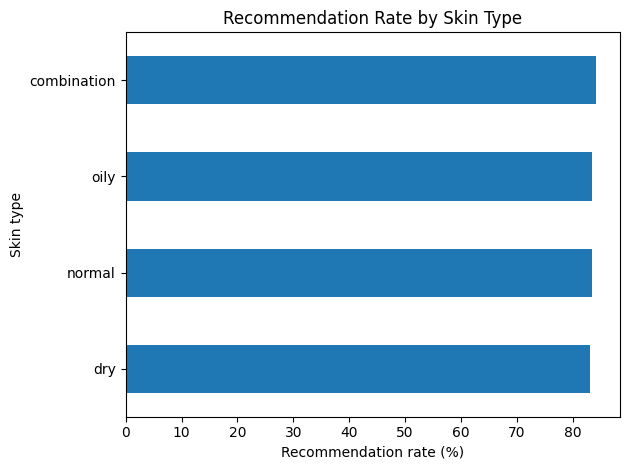

In [7]:

import matplotlib.pyplot as plt

plot_data = summary.sort_values(
    "recommendation_rate_percent",
    ascending=True
)

plot_data["recommendation_rate_percent"].plot(
    kind="barh"
)

plt.title("Recommendation Rate by Skin Type")
plt.xlabel("Recommendation rate (%)")
plt.ylabel("Skin type")
plt.tight_layout()
plt.show()


In [8]:

import pandas as pd

# Product IDs from the catalogue
products = pd.read_csv("product_info.csv")
product_ids = set(products["product_id"].dropna().astype(str).str.strip())

matched = 0
unmatched = 0
missing_product_id = 0
missing_recommendation = 0
total = 0

# Check review-to-product matching in chunks
for chunk in pd.read_csv(
    "reviews_0-250.csv",
    usecols=["product_id", "is_recommended"],
    chunksize=100_000,
    low_memory=False
):
    total += len(chunk)

    ids = chunk["product_id"].astype("string").str.strip()
    has_id = ids.notna() & ids.ne("")

    missing_product_id += int((~has_id).sum())
    matched += int(ids[has_id].isin(product_ids).sum())
    unmatched += int((~ids[has_id].isin(product_ids)).sum())

    missing_recommendation += int(
        chunk["is_recommended"].isna().sum()
    )

print("TOTAL REVIEWS:", total)
print("Matched review rows:", matched)
print("Unmatched review rows with an ID:", unmatched)
print("Reviews missing product ID:", missing_product_id)
print("Reviews missing recommendation:", missing_recommendation)

if total:
    print(
        "Product ID match rate (%):",
        round(matched / total * 100, 2)
    )
    print(
        "Missing recommendation (%):",
        round(missing_recommendation / total * 100, 2)
    )


TOTAL REVIEWS: 602130
Matched review rows: 602130
Unmatched review rows with an ID: 0
Reviews missing product ID: 0
Reviews missing recommendation: 117486
Product ID match rate (%): 100.0
Missing recommendation (%): 19.51
